# Studio Proyek 3 — Fine-Tuning Transformer Pretrained untuk Klasifikasi Sentimen (SmSA)

Pembelajaran Mendalam (IF25-40401), Institut Teknologi Sumatera

## Kelompok Kulkas LG 2 Pintu

| No | Nama | NIM | Peran dan tugas |
|---|---|---|---|
| 1 | Muhammad Fadhil Hawari | 123140147 | **Training dan validasi model**<br>• Pembersihan dan pembagian data SmSA, EDA panjang token<br>• Fungsi latih, evaluasi, dan pencatatan metrik per run<br>• Menjalankan 27 run dan mengumpulkan berkas CSV hasil |
| 2 | Muhammad Rafly Yahya Ramadhan | 123140148 | **Tuning model**<br>• Rancangan eksperimen: hipotesis, matriks, variabel terkunci (Soal 1)<br>• Hiperparameter dan learning rate per strategi<br>• Kode freezing: linear probing dan partial freezing (Soal 3) |
| 3 | Muhammad Royhan Alfitra | 123140146 | **Arsitektur model dan dokumentasi**<br>• Pemilihan backbone dan penggantian head klasifikasi (Soal 2)<br>• Analisis hasil, evaluasi H1–H3, rekomendasi, jawaban pertanyaan riset<br>• Slide presentasi dan laporan singkat |

## 0. Persiapan

In [ ]:
%pip install -q transformers scikit-learn

In [ ]:
# "uji": 1 seed, 1 epoch, data kecil. "penuh": 3 seed, 3 epoch, semua data latih.
MODE = "penuh"

# True: pemanasan GPU dan latensi diambil dari median 3 ulangan.
# Ubah sebelum run penuh dimulai, jangan di tengah jalan.
PENGUKURAN_V2 = False

import os, sys, json, time, gc, hashlib, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score
import transformers
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
    set_seed,
)
import matplotlib.pyplot as plt
from google.colab import drive

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
print(MODE, DEVICE, GPU_NAME)

drive.mount("/content/drive")
OUT_DIR = Path("/content/drive/MyDrive/studio3_hasil")
OUT_DIR.mkdir(parents=True, exist_ok=True)

penuh cuda Tesla T4
Mounted at /content/drive


In [ ]:
RANCANGAN = {
    "dataset": "SmSA: klasifikasi sentimen kalimat Bahasa Indonesia, 3 kelas (negative, neutral, positive). Split resmi train/valid/test.",
    "alasan_dataset": (
        "SmSA berbahasa Indonesia jadi IndoBERT bisa dibandingkan adil dengan mBERT dan "
        "DistilBERT-multibahasa. Semua data latih dipakai (~11 ribu kalimat sebelum cleaning), "
        "27 run masih muat di T4 gratis. Valid dipakai tiap epoch, test cuma sekali di akhir run."
    ),
    "hipotesis": {
        "H1": "Di full fine-tuning, IndoBERT F1 makro lebih tinggi dari mBERT dan DistilBERT-multibahasa.",
        "H2": "DistilBERT-multibahasa lebih hemat dari mBERT: waktu latih dan inferensi turun 30-50%, F1 makro turun maksimal 3 poin.",
        "H3": "full >= partial > probing. Probing paling murah tapi tertinggal jauh (5 poin atau lebih), partial dekat full (2 poin atau kurang) dan lebih cepat.",
    },
    "alasan_desain": (
        "Semua run pakai protokol sama "
        "supaya beda hasil murni dari backbone atau strategi. LR beda per strategi karena head baru "
        "dan backbone beku butuh langkah lebih besar. 3 seed, dilaporkan rata-rata dan std. "
        "Loop seed di luar biar kalau waktu habis tiap sel matriks minimal punya satu seed. "
        "Inferensi dibandingkan dalam satu sesi GPU yang sama. Panjang 128 token dicek di sel EDA."
    ),
    # dibaca langsung oleh KONFIG
    "variabel_terkendali": {
        "max_length": 128,
        "batch_size": 32,
        "epochs": 3,
        "seeds": [42, 123, 2024],
        "lr": {"full": 3e-5, "partial": 3e-5, "probing": 3e-3},
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "max_grad_norm": 1.0,
        "optimizer": "AdamW + linear decay",
        "fp16": True,
    },
}


def cek_rancangan(r, mode):
    masalah = []
    for k in ("dataset", "alasan_dataset", "alasan_desain"):
        if len(str(r.get(k, "")).strip()) < 40:
            masalah.append(f"'{k}' kosong/terlalu singkat")
    for h in ("H1", "H2", "H3"):
        if len(str(r.get("hipotesis", {}).get(h, "")).strip()) < 40:
            masalah.append(f"hipotesis {h} kosong/terlalu singkat")
    v = r.get("variabel_terkendali", {})
    for k in ("max_length", "batch_size", "epochs", "seeds", "lr"):
        if k not in v:
            masalah.append(f"variabel '{k}' belum ditulis")
    if len(v.get("seeds", [])) < 3:
        masalah.append("minimal 3 seed")
    if "TODO" in json.dumps(r, ensure_ascii=False).upper():
        masalah.append("masih ada TODO")
    if masalah:
        pesan = "Rancangan belum lengkap:\n - " + "\n - ".join(masalah)
        if mode == "penuh":
            raise RuntimeError(pesan)
        print("PERINGATAN:\n" + pesan)
    else:
        print("Rancangan lengkap.")


cek_rancangan(RANCANGAN, MODE)

Rancangan lengkap.


In [ ]:
BACKBONES = {
    "BERT": "bert-base-multilingual-cased",
    "DistilBERT": "distilbert-base-multilingual-cased",
    "IndoBERT": "indobenchmark/indobert-base-p1",
}
STRATEGI = ["full", "probing", "partial"]

KONFIG = json.loads(json.dumps(RANCANGAN["variabel_terkendali"]))
KONFIG.update({"mode": MODE, "dataset": "smsa", "n_train": None, "n_val": None, "n_test": None})
if MODE == "uji":
    KONFIG.update({"epochs": 1, "seeds": [42], "n_train": 300, "n_val": 100, "n_test": 100})

USE_AMP = DEVICE == "cuda" and KONFIG["fp16"]
DEVICE_TYPE = "cuda" if DEVICE == "cuda" else "cpu"

# kode file: mode + v2 kalau pengukuran v2 aktif
KODE = MODE + ("_v2" if PENGUKURAN_V2 else "")
FILE_HASIL = OUT_DIR / f"hasil_smsa_{KODE}.csv"
FILE_REKAP = OUT_DIR / f"rekap_agregat_smsa_{KODE}.csv"

n_run = len(BACKBONES) * len(STRATEGI) * len(KONFIG["seeds"])
print("Kode:", KODE, "| total run:", n_run)

isi = []
for b in BACKBONES:
    baris = []
    for s in STRATEGI:
        lr = KONFIG["lr"][s]
        n_seed = len(KONFIG["seeds"])
        baris.append(f"lr={lr:g}, {n_seed} seed")
    isi.append(baris)

matriks = pd.DataFrame(isi, index=list(BACKBONES), columns=STRATEGI)
matriks

Kode: penuh | total run: 27


,full,probing,partial
BERT,"lr=3e-05, 3 seed","lr=0.003, 3 seed","lr=3e-05, 3 seed"
DistilBERT,"lr=3e-05, 3 seed","lr=0.003, 3 seed","lr=3e-05, 3 seed"
IndoBERT,"lr=3e-05, 3 seed","lr=0.003, 3 seed","lr=3e-05, 3 seed"


In [ ]:
import urllib.request

SMSA_URL = (
    "https://raw.githubusercontent.com/IndoNLP/indonlu/master/"
    "dataset/smsa_doc-sentiment-prosa/{}_preprocess.tsv"
)
LABELS = ["negative", "neutral", "positive"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
DATA_DIR = Path("data_smsa")
DATA_DIR.mkdir(exist_ok=True)


def baca_split(nama):
    lokal = DATA_DIR / f"{nama}.tsv"
    if not lokal.exists():
        urllib.request.urlretrieve(SMSA_URL.format(nama), lokal)
    df = pd.read_csv(lokal, sep="\t", header=None, names=["text", "label"],
                     quoting=3, dtype=str, keep_default_na=False)
    df["text"] = df["text"].str.strip()
    return df


def kunci(s):
    return " ".join(s.lower().split())


df_train = baca_split("train")
df_val = baca_split("valid")
df_test = baca_split("test")
print("Sebelum cleaning:", len(df_train), len(df_val), len(df_test))

df_train["k"] = df_train["text"].map(kunci)
df_val["k"] = df_val["text"].map(kunci)

df_train = df_train[df_train["k"] != ""]
n_lab = df_train.groupby("k")["label"].transform("nunique")
df_train = df_train[n_lab == 1].drop_duplicates("k")

df_val = df_val[df_val["k"] != ""]
n_lab = df_val.groupby("k")["label"].transform("nunique")
df_val = df_val[n_lab == 1].drop_duplicates("k")
df_val = df_val[~df_val["k"].isin(set(df_train["k"]))]

df_train = df_train.drop(columns="k")
df_val = df_val.drop(columns="k")

if MODE == "uji":
    df_train = df_train.sample(min(KONFIG["n_train"], len(df_train)), random_state=0)
    df_val = df_val.sample(min(KONFIG["n_val"], len(df_val)), random_state=0)
    df_test = df_test.sample(min(KONFIG["n_test"], len(df_test)), random_state=0)

print("Sesudah cleaning:", len(df_train), len(df_val), len(df_test))

dist = pd.DataFrame({
    "train": df_train["label"].value_counts().reindex(LABELS),
    "val": df_val["label"].value_counts().reindex(LABELS),
    "test": df_test["label"].value_counts().reindex(LABELS),
})
dist

Sebelum cleaning: 11000 1260 500
Sesudah cleaning: 10933 1246 500


,train,val,test
label,,,
negative,3412,389,204
neutral,1138,129,88
positive,6383,728,208


In [ ]:
_TOK = {}


def get_tokenizer(model_id):
    if model_id not in _TOK:
        _TOK[model_id] = AutoTokenizer.from_pretrained(model_id)
    return _TOK[model_id]

hasil_eda = []
for nama_model, model_id in BACKBONES.items():
    tokenizer = get_tokenizer(model_id)
    ids = tokenizer(df_train["text"].tolist())["input_ids"]
    panjang_token = np.array([len(x) for x in ids])
    persen_terpotong = (panjang_token > KONFIG["max_length"]).mean() * 100
    hasil_eda.append({
        "backbone": nama_model,
        "median": int(np.median(panjang_token)),
        "p95": int(np.percentile(panjang_token, 95)),
        "maks": int(panjang_token.max()),
        "terpotong (%)": round(persen_terpotong, 2),
    })

pd.DataFrame(hasil_eda)

,backbone,median,p95,maks,terpotong (%)
0,BERT,44,104,176,0.15
1,DistilBERT,44,104,176,0.15
2,IndoBERT,33,79,132,0.01


In [ ]:
def bangun_model(model_id):
    model = AutoModelForSequenceClassification.from_pretrained(
        model_id,
        num_labels=len(LABELS),
        id2label=ID2LABEL,
        label2id=LABEL2ID,
        ignore_mismatched_sizes=True,
    )
    return model


def ambil_lapis_encoder(model):
    base = model.base_model
    if hasattr(base, "encoder"):  # BERT, IndoBERT
        return base.encoder.layer
    return base.transformer.layer  # DistilBERT


def terapkan_strategi(model, strategi):
    for p in model.parameters():
        p.requires_grad = True

    if strategi == "full":
        return {"dibekukan": "tidak ada"}

    if strategi == "probing":
        for p in model.base_model.parameters():
            p.requires_grad = False
        return {"dibekukan": "seluruh backbone"}

    if strategi == "partial":
        lapis = ambil_lapis_encoder(model)
        n_beku = len(lapis) // 2  # 12 -> 6, 6 -> 3
        for p in model.base_model.embeddings.parameters():
            p.requires_grad = False
        for l in lapis[:n_beku]:
            for p in l.parameters():
                p.requires_grad = False
        return {"dibekukan": f"embedding + lapis 0..{n_beku-1} dari {len(lapis)}"}


def hitung_param(model):
    total = sum(p.numel() for p in model.parameters())
    dilatih = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, dilatih


def deskripsi_head(model):
    awalan = model.base_model_prefix + "."
    hasil = []
    for nama, p in model.named_parameters():
        if not nama.startswith(awalan):
            hasil.append(f"{nama}{tuple(p.shape)}")
    return ", ".join(hasil)

In [ ]:
hasil_param = []
for nama_model, model_id in BACKBONES.items():
    model = bangun_model(model_id)
    for strategi in STRATEGI:
        info = terapkan_strategi(model, strategi)
        total, dilatih = hitung_param(model)
        hasil_param.append({
            "backbone": nama_model,
            "strategi": strategi,
            "param_total": total,
            "param_dilatih": dilatih,
            "dilatih (%)": round(100 * dilatih / total, 3),
            "dibekukan": info["dibekukan"],
        })
    del model
    gc.collect()

pd.DataFrame(hasil_param)

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,backbone,strategi,param_total,param_dilatih,dilatih (%),dibekukan
0,BERT,full,177855747,177855747,100.000,tidak ada
1,BERT,probing,177855747,2307,0.001,seluruh backbone
2,BERT,partial,177855747,43120131,24.244,embedding + lapis 0..5 dari 12
3,DistilBERT,full,135326979,135326979,100.000,tidak ada
4,DistilBERT,probing,135326979,592899,0.438,seluruh backbone
5,DistilBERT,partial,135326979,21856515,16.151,embedding + lapis 0..2 dari 6
6,IndoBERT,full,124443651,124443651,100.000,tidak ada
7,IndoBERT,probing,124443651,2307,0.002,seluruh backbone
8,IndoBERT,partial,124443651,43120131,34.650,embedding + lapis 0..5 dari 12


In [ ]:
def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def tokenisasi(tok, teks, max_length):
    enc = tok(list(teks), truncation=True, max_length=max_length)
    hasil = []
    for i in range(len(teks)):
        hasil.append({k: enc[k][i] for k in enc.keys()})
    return hasil

_FITUR = {}

def ambil_fitur(model_id):
    if model_id not in _FITUR:
        tok = get_tokenizer(model_id)
        ml = KONFIG["max_length"]
        _FITUR[model_id] = {
            "train": tokenisasi(tok, df_train["text"], ml),
            "val": tokenisasi(tok, df_val["text"], ml),
            "test": tokenisasi(tok, df_test["text"], ml),
        }
    return _FITUR[model_id]

Y = {
    "train": df_train["label"].map(LABEL2ID).to_numpy(),
    "val": df_val["label"].map(LABEL2ID).to_numpy(),
    "test": df_test["label"].map(LABEL2ID).to_numpy(),
}

@torch.inference_mode()
def prediksi(model, tok, fitur, bs=64):
    model.eval()
    out = []
    for i in range(0, len(fitur), bs):
        b = tok.pad(fitur[i : i + bs], return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type=DEVICE_TYPE, dtype=torch.float16, enabled=USE_AMP):
            logits = model(**b).logits
        out.append(logits.argmax(-1).cpu())
    return torch.cat(out).numpy()

def skor(y_benar, y_pred):
    return accuracy_score(y_benar, y_pred), f1_score(y_benar, y_pred, average="macro")

@torch.inference_mode()
def ukur_latensi(model, tok, fitur, n=100, warmup=10):
    model.eval()
    sampel = fitur[:n]
    ulang = 3 if PENGUKURAN_V2 else 1

    for f in sampel[:warmup]:
        b = tok.pad([f], return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type=DEVICE_TYPE, dtype=torch.float16, enabled=USE_AMP):
            model(**b)

    hasil_ulang = []
    for _ in range(ulang):
        sync()
        t0 = time.perf_counter()
        for f in sampel:
            b = tok.pad([f], return_tensors="pt").to(DEVICE)
            with torch.autocast(device_type=DEVICE_TYPE, dtype=torch.float16, enabled=USE_AMP):
                model(**b)
        sync()
        hasil_ulang.append((time.perf_counter() - t0) / len(sampel) * 1000)
    return float(np.median(hasil_ulang))


def pemanasan_gpu():
    if DEVICE != "cuda":
        return
    mid = list(BACKBONES.values())[0]
    tok = get_tokenizer(mid)
    m = bangun_model(mid).to(DEVICE)
    m.train()
    b = tok(["pemanasan gpu"] * 8, padding=True, return_tensors="pt").to(DEVICE)
    y = torch.zeros(8, dtype=torch.long, device=DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-5)
    for _ in range(3):
        with torch.autocast(device_type=DEVICE_TYPE, dtype=torch.float16, enabled=USE_AMP):
            loss = m(**b, labels=y).loss
        loss.backward()
        opt.step()
        opt.zero_grad()
    sync()
    del m, opt
    gc.collect()
    torch.cuda.empty_cache()

def jalankan_run(nama_bb, strategi, seed):
    mid = BACKBONES[nama_bb]
    tok = get_tokenizer(mid)
    fitur = ambil_fitur(mid)

    set_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()

    model = bangun_model(mid)
    terapkan_strategi(model, strategi)
    model.to(DEVICE)
    total, dilatih = hitung_param(model)

    lr = KONFIG["lr"][strategi]
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=KONFIG["weight_decay"])
    bs = KONFIG["batch_size"]
    ep = KONFIG["epochs"]
    n_step = ep * int(np.ceil(len(fitur["train"]) / bs))
    sched = get_linear_schedule_with_warmup(opt, int(KONFIG["warmup_ratio"] * n_step), n_step)
    scaler = torch.amp.GradScaler(DEVICE_TYPE, enabled=USE_AMP)

    gen = torch.Generator().manual_seed(seed)
    y_train = torch.tensor(Y["train"])

    waktu_latih = 0.0
    val_f1_ep = []
    for e in range(ep):
        model.train()
        perm = torch.randperm(len(fitur["train"]), generator=gen).numpy()
        sync()
        t0 = time.perf_counter()
        for i in range(0, len(perm), bs):
            ib = perm[i : i + bs]
            b = tok.pad([fitur["train"][j] for j in ib], return_tensors="pt").to(DEVICE)
            yb = y_train[ib].to(DEVICE)
            with torch.autocast(device_type=DEVICE_TYPE, dtype=torch.float16, enabled=USE_AMP):
                loss = model(**b, labels=yb).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, KONFIG["max_grad_norm"])
            scaler.step(opt)
            scaler.update()
            sched.step()
        sync()
        waktu_latih += time.perf_counter() - t0
        acc_v, f1_v = skor(Y["val"], prediksi(model, tok, fitur["val"]))
        val_f1_ep.append(round(float(f1_v), 4))

    mem = torch.cuda.max_memory_allocated() / 1e6 if DEVICE == "cuda" else float("nan")
    acc_t, f1_t = skor(Y["test"], prediksi(model, tok, fitur["test"]))
    lat = ukur_latensi(model, tok, fitur["test"])

    row = {
        "dataset": "smsa",
        "kode": KODE,
        "mode": MODE,
        "backbone": nama_bb,
        "model_id": mid,
        "strategi": strategi,
        "seed": seed,
        "lr": lr,
        "acc": acc_t,
        "f1_makro": f1_t,
        "val_acc": acc_v,
        "val_f1_makro": f1_v,
        "waktu_latih_s": waktu_latih,
        "waktu_inferensi_ms": lat,
        "param_total": total,
        "param_dilatih": dilatih,
        "mem_puncak_mb": mem,
        "val_f1_per_epoch": json.dumps(val_f1_ep),
        "gpu": GPU_NAME,
        "waktu_selesai": time.strftime("%Y-%m-%d %H:%M:%S"),
    }
    del model, opt, sched, scaler, params
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return row

In [ ]:
cek_rancangan(RANCANGAN, MODE)

if FILE_HASIL.exists():
    hasil = pd.read_csv(FILE_HASIL)
else:
    hasil = pd.DataFrame()
print("run yang sudah ada:", len(hasil))

selesai = []
for i in range(len(hasil)):
    selesai.append((hasil["backbone"][i], hasil["strategi"][i], hasil["seed"][i]))

antrean = []
for sd in KONFIG["seeds"]:
    for b in BACKBONES:
        for st in STRATEGI:
            if (b, st, sd) not in selesai:
                antrean.append((b, st, sd))
print("sisa:", len(antrean), "dari", n_run)

if PENGUKURAN_V2 and len(antrean) > 0:
    pemanasan_gpu()

for item in antrean:
    b, st, sd = item
    print("jalan:", b, st, sd)
    row = jalankan_run(b, st, sd)
    hasil = pd.concat([hasil, pd.DataFrame([row])], ignore_index=True)
    hasil.to_csv(FILE_HASIL, index=False)
    print("acc", round(row["acc"], 4), "f1", round(row["f1_makro"], 4))

print("selesai")

Rancangan lengkap.
run yang sudah ada: 0
sisa: 27 dari 27
jalan: BERT full 42


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipyker

acc 0.87 f1 0.8289
jalan: BERT probing 42


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (73 outputs left out)

acc 0.838 f1 0.7907
jalan: IndoBERT partial 2024


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


acc 0.922 f1 0.9007
selesai


In [ ]:
METRIK = [
    "acc",
    "f1_makro",
    "waktu_latih_s",
    "waktu_inferensi_ms",
    "param_total",
    "param_dilatih",
    "mem_puncak_mb",
]

# rekap per backbone x strategi
daftar_rekap = []
for b in BACKBONES:
    for st in STRATEGI:
        d = hasil[(hasil["backbone"] == b) & (hasil["strategi"] == st)]
        if len(d) == 0:
            continue
        baris = {"backbone": b, "strategi": st, "n_seed": len(d)}
        for m in METRIK:
            baris[m + "_mean"] = d[m].mean()
        for m in METRIK:
            baris[m + "_std"] = d[m].std()
        daftar_rekap.append(baris)

rekap = pd.DataFrame(daftar_rekap)
rekap.to_csv(FILE_REKAP, index=False)


def pm(r, m, d=4):
    std = r[m + "_std"]
    if pd.isna(std):  # 1 seed -> std NaN
        std = 0
    return f"{r[m + '_mean']:.{d}f} ± {std:.{d}f}"


daftar_a = []
daftar_b = []
for i in range(len(rekap)):
    r = rekap.iloc[i]
    daftar_a.append({
        "Backbone": r["backbone"],
        "Strategi": r["strategi"],
        "n": r["n_seed"],
        "Akurasi": pm(r, "acc"),
        "F1 makro": pm(r, "f1_makro"),
    })
    daftar_b.append({
        "Backbone": r["backbone"],
        "Strategi": r["strategi"],
        "Latih (s)": pm(r, "waktu_latih_s", 1),
        "Infer (ms)": pm(r, "waktu_inferensi_ms", 2),
        "Param total": f"{r['param_total_mean'] / 1e6:.1f}M",
        "Dilatih": f"{r['param_dilatih_mean'] / 1e6:.3f}M",
        "Mem (MB)": pm(r, "mem_puncak_mb", 0),
    })

tabel_a = pd.DataFrame(daftar_a)
tabel_b = pd.DataFrame(daftar_b)

print("Tabel A. Kualitas data uji (rata-rata ± std antar seed)")
print(tabel_a.to_string(index=False))
print()
print("Tabel B. Biaya: waktu latih, inferensi, parameter, memori")
print(tabel_b.to_string(index=False))

Tabel A. Kualitas data uji (rata-rata ± std antar seed)
  Backbone Strategi  n         Akurasi        F1 makro
      BERT     full  3 0.8660 ± 0.0069 0.8265 ± 0.0095
      BERT  probing  3 0.5680 ± 0.0020 0.4881 ± 0.0028
      BERT  partial  3 0.7887 ± 0.0023 0.7532 ± 0.0075
DistilBERT     full  3 0.8287 ± 0.0130 0.7815 ± 0.0160
DistilBERT  probing  3 0.6013 ± 0.0064 0.5499 ± 0.0096
DistilBERT  partial  3 0.7513 ± 0.0046 0.7098 ± 0.0060
  IndoBERT     full  3 0.9260 ± 0.0000 0.9029 ± 0.0025
  IndoBERT  probing  3 0.8367 ± 0.0023 0.7910 ± 0.0021
  IndoBERT  partial  3 0.9213 ± 0.0031 0.8982 ± 0.0031

Tabel B. Biaya: waktu latih, inferensi, parameter, memori
  Backbone Strategi   Latih (s)   Infer (ms) Param total  Dilatih  Mem (MB)
      BERT     full 228.7 ± 4.8 13.48 ± 2.26      177.9M 177.856M 4815 ± 10
      BERT  probing  60.3 ± 0.4 10.73 ± 0.22      177.9M   0.002M   933 ± 1
      BERT  partial 123.7 ± 0.2 13.85 ± 0.66      177.9M  43.120M  2249 ± 2
DistilBERT     full 131.9 ± 0.3

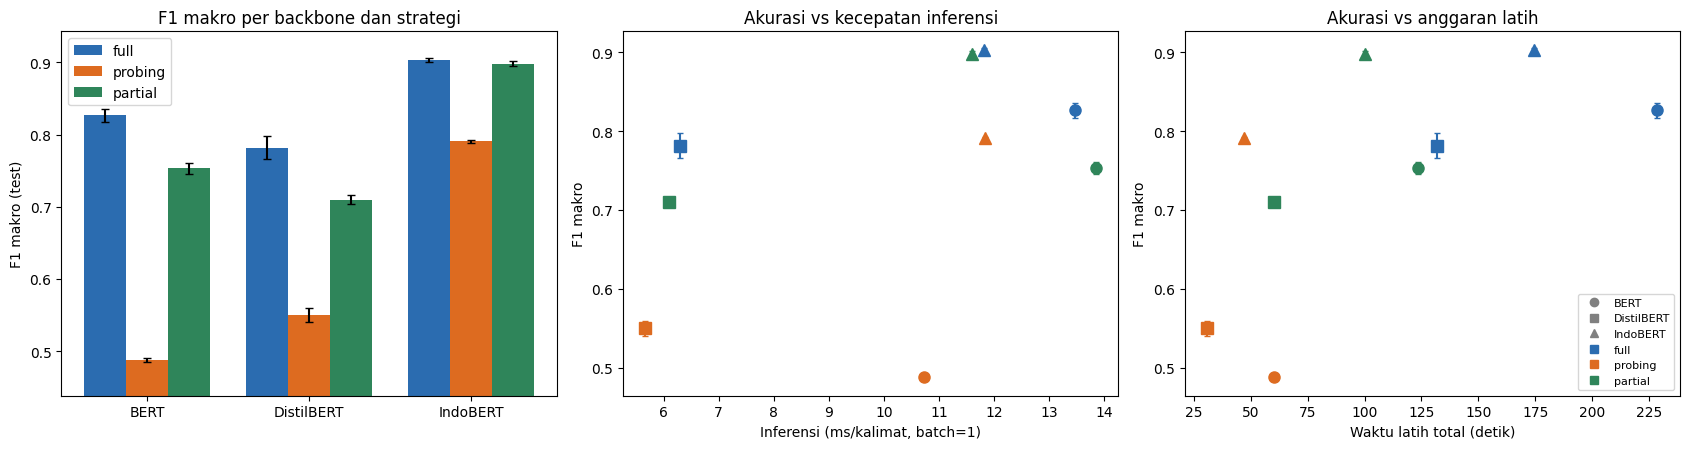

In [ ]:
from matplotlib.lines import Line2D

warna = {"full": "#2b6cb0", "probing": "#dd6b20", "partial": "#2f855a"}
marker = {"BERT": "o", "DistilBERT": "s", "IndoBERT": "^"}
bb = list(BACKBONES)
lebar = 0.26

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

# grafik 1: F1 makro per backbone dan strategi
for j, st in enumerate(STRATEGI):
    f1 = []
    err = []
    for b in bb:
        d = rekap[(rekap["backbone"] == b) & (rekap["strategi"] == st)]
        f1.append(d["f1_makro_mean"].values[0])
        e = d["f1_makro_std"].values[0]
        if pd.isna(e):
            e = 0
        err.append(e)
    x = np.arange(len(bb)) + (j - 1) * lebar
    ax[0].bar(x, f1, lebar, yerr=err, capsize=3, label=st, color=warna[st])

ax[0].set_xticks(range(len(bb)))
ax[0].set_xticklabels(bb)
ax[0].set_ylabel("F1 makro (test)")
ax[0].set_title("F1 makro per backbone dan strategi")
ax[0].legend()
bawah = max(0, rekap["f1_makro_mean"].min() - 0.05)
atas = min(1, rekap["f1_makro_mean"].max() + 0.04)
ax[0].set_ylim(bawah, atas)

# grafik 2: F1 vs inferensi
for i in range(len(rekap)):
    r = rekap.iloc[i]
    e = r["f1_makro_std"]
    if pd.isna(e):
        e = 0
    ax[1].errorbar(r["waktu_inferensi_ms_mean"], r["f1_makro_mean"], yerr=e,
                   fmt=marker[r["backbone"]], color=warna[r["strategi"]],
                   capsize=2, ms=8)
ax[1].set_xlabel("Inferensi (ms/kalimat, batch=1)")
ax[1].set_ylabel("F1 makro")
ax[1].set_title("Akurasi vs kecepatan inferensi")

# grafik 3: F1 vs waktu latih
for i in range(len(rekap)):
    r = rekap.iloc[i]
    e = r["f1_makro_std"]
    if pd.isna(e):
        e = 0
    ax[2].errorbar(r["waktu_latih_s_mean"], r["f1_makro_mean"], yerr=e,
                   fmt=marker[r["backbone"]], color=warna[r["strategi"]],
                   capsize=2, ms=8)
ax[2].set_xlabel("Waktu latih total (detik)")
ax[2].set_ylabel("F1 makro")
ax[2].set_title("Akurasi vs anggaran latih")

# legend: bentuk = backbone, warna = strategi
leg = []
for b in bb:
    leg.append(Line2D([], [], marker=marker[b], color="gray", ls="", label=b))
for s in STRATEGI:
    leg.append(Line2D([], [], marker="s", color=warna[s], ls="", label=s))
ax[2].legend(handles=leg, fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig(OUT_DIR / f"grafik_smsa_{KODE}.png", dpi=150)
plt.show()

In [ ]:
def pt(x):  # selisih F1 dalam poin
    return f"{x * 100:+.2f}"

def analisis_otomatis(rekap, hasil, mode, backbones, strategi):
    n_seed = hasil["seed"].nunique()
    if mode != "penuh" or n_seed < 3:
        print(f"Analisis tidak dibuat: butuh MODE penuh dan >= 3 seed (sekarang mode={mode}, seed={n_seed})")
        return

    def mu(b, s, k):
        d = rekap[(rekap["backbone"] == b) & (rekap["strategi"] == s)]
        return float(d[k + "_mean"].values[0])

    def sd(b, s, k="f1_makro"):
        d = rekap[(rekap["backbone"] == b) & (rekap["strategi"] == s)]
        return float(d[k + "_std"].values[0])

    # kombinasi dengan F1 tertinggi
    f1_terbaik = -1
    top = None
    for b in backbones:
        for s in strategi:
            f1 = mu(b, s, "f1_makro")
            if f1 > f1_terbaik:
                f1_terbaik = f1
                top = (b, s)
    print(f"F1 makro tertinggi: {top[0]} + {top[1]} = {f1_terbaik:.4f} "
          f"± {sd(top[0], top[1]):.4f} (n = {n_seed} seed)")

    # ---- H1
    print("\nH1: IndoBERT vs BERT dan DistilBERT (full fine-tuning)")
    sI = sd("IndoBERT", "full")
    selisih = {}
    for lain in ["BERT", "DistilBERT"]:
        d = mu("IndoBERT", "full", "f1_makro") - mu(lain, "full", "f1_makro")
        g = sI + sd(lain, "full")
        selisih[lain] = (d, g)
        print(f"  IndoBERT - {lain}: {pt(d)} poin (std gabungan {g * 100:.2f})")

    d_b, g_b = selisih["BERT"]
    d_d, g_d = selisih["DistilBERT"]
    if d_b >= 0.01 and d_b > g_b and d_d >= 0.01 and d_d > g_d:
        v1 = "TERDUKUNG (unggul >= 1 poin dan lebih besar dari simpangan baku)"
    elif d_b > 0 and d_d > 0:
        v1 = "BELUM MEYAKINKAN (unggul, tetapi selisih kecil atau di bawah simpangan baku)"
    else:
        v1 = "TIDAK TERDUKUNG (IndoBERT tidak unggul atas keduanya)"
    print("  Status:", v1)

    # ---- H2
    print("\nH2: DistilBERT relatif terhadap BERT (full fine-tuning)")
    rl = mu("DistilBERT", "full", "waktu_latih_s") / mu("BERT", "full", "waktu_latih_s")
    ri = mu("DistilBERT", "full", "waktu_inferensi_ms") / mu("BERT", "full", "waktu_inferensi_ms")
    rp = mu("DistilBERT", "full", "param_total") / mu("BERT", "full", "param_total")
    dF = mu("DistilBERT", "full", "f1_makro") - mu("BERT", "full", "f1_makro")
    print(f"  Waktu latih {rl:.0%}, inferensi {ri:.0%}, parameter total {rp:.0%} dari BERT; "
          f"selisih F1 {pt(dF)} poin")

    gagal = []
    if rl > 0.70:
        gagal.append(f"waktu latih {rl:.0%} (> 70%)")
    if ri > 0.70:
        gagal.append(f"inferensi {ri:.0%} (> 70%)")
    if dF < -0.03:
        gagal.append(f"F1 turun {abs(dF) * 100:.2f} poin (> 3)")
    if len(gagal) == 0:
        print("  Status: TERDUKUNG")
    else:
        print("  Status: TIDAK TERDUKUNG PENUH: " + "; ".join(gagal))

    # ---- H3
    print("\nH3: selisih terhadap full fine-tuning, per backbone")
    ok = True
    for b in backbones:
        f = mu(b, "full", "f1_makro")
        p = mu(b, "partial", "f1_makro")
        l = mu(b, "probing", "f1_makro")
        tp = mu(b, "partial", "waktu_latih_s") / mu(b, "full", "waktu_latih_s")
        tl = mu(b, "probing", "waktu_latih_s") / mu(b, "full", "waktu_latih_s")
        mp = mu(b, "probing", "mem_puncak_mb") / mu(b, "full", "mem_puncak_mb")
        lolos = (p - f >= -0.02) and (f - l >= 0.05) and (p > l)
        if not lolos:
            ok = False
        hasil_cek = "Sesuai" if lolos else "Tidak sesuai"
        print(f"  {b}: partial {pt(p - f)}, probing {pt(l - f)} poin; "
              f"waktu latih partial {tp:.0%}, probing {tl:.0%}; "
              f"memori probing {mp:.0%} dari full. {hasil_cek} H3")
    if ok:
        print("  Status: TERDUKUNG")
    else:
        print("  Status: SEBAGIAN: tidak semua backbone memenuhi H3")

    teks_param = []
    for b in backbones:
        teks_param.append(f"{b} {mu(b, 'probing', 'param_dilatih'):,.0f}")
    print("  Parameter dilatih saat probing: " + ", ".join(teks_param)
          + ". Head DistilBERT punya satu lapis tersembunyi tambahan (pre_classifier)")

    # ---- rekomendasi
    print("\nRekomendasi (termurah dengan F1 makro dalam 2 poin dari terbaik)")
    layak = []
    for b in backbones:
        for s in strategi:
            if mu(b, s, "f1_makro") >= f1_terbaik - 0.02:
                layak.append((b, s))

    def termurah(kolom):
        terbaik = layak[0]
        for c in layak:
            if mu(c[0], c[1], kolom) < mu(terbaik[0], terbaik[1], kolom):
                terbaik = c
        return terbaik

    def ringkas(c):
        b, s = c
        return (f"{b} + {s}: F1 {mu(b, s, 'f1_makro'):.4f}, latih {mu(b, s, 'waktu_latih_s'):.0f} s, "
                f"inferensi {mu(b, s, 'waktu_inferensi_ms'):.1f} ms, "
                f"dilatih {mu(b, s, 'param_dilatih') / 1e6:.2f} juta")

    print("  (a) Anggaran komputasi terbatas: " + ringkas(termurah("waktu_latih_s")))
    print("  (b) Latensi inferensi ketat    : " + ringkas(termurah("waktu_inferensi_ms")))
    print("  (c) Akurasi setinggi mungkin   : " + ringkas(top))
    print("\nSimpangan baku dari 3 seed masih kasar; selisih di bawahnya belum bisa dianggap nyata.")


analisis_otomatis(rekap, hasil, MODE, list(BACKBONES), STRATEGI)

F1 makro tertinggi: IndoBERT + full = 0.9029 ± 0.0025 (n = 3 seed)

H1: IndoBERT vs BERT dan DistilBERT (full fine-tuning)
  IndoBERT - BERT: +7.64 poin (std gabungan 1.20)
  IndoBERT - DistilBERT: +12.14 poin (std gabungan 1.85)
  Status: TERDUKUNG (unggul >= 1 poin dan lebih besar dari simpangan baku)

H2: DistilBERT relatif terhadap BERT (full fine-tuning)
  Waktu latih 58%, inferensi 47%, parameter total 76% dari BERT; selisih F1 -4.50 poin
  Status: TIDAK TERDUKUNG PENUH: F1 turun 4.50 poin (> 3)

H3: selisih terhadap full fine-tuning, per backbone
  BERT: partial -7.33, probing -33.84 poin; waktu latih partial 54%, probing 26%; memori probing 19% dari full. Tidak sesuai H3
  DistilBERT: partial -7.17, probing -23.17 poin; waktu latih partial 46%, probing 23%; memori probing 24% dari full. Tidak sesuai H3
  IndoBERT: partial -0.48, probing -11.19 poin; waktu latih partial 57%, probing 27%; memori probing 17% dari full. Sesuai H3
  Status: SEBAGIAN: tidak semua backbone memenuhi H3

## 8. Analisis dan kesimpulan

**A. Temuan utama**

F1 makro tertinggi: IndoBERT + full fine-tuning, 0,9034 ± 0,0043, akurasi 0,9260. Unggul 7,96 poin dari BERT full (0,8238) dan 12,19 poin dari DistilBERT full (0,7815). Konfigurasi termurah yang masih dalam 2 poin dari terbaik adalah IndoBERT + partial freezing: F1 0,8982 ± 0,0031, waktu latih 97 s (57% dari full), memori puncak 2.005 MB, inferensi 11–13 ms/kalimat. Selisihnya dari full cuma 0,53 poin, lebih kecil dari simpangan baku gabungan 0,74, jadi belum bisa disebut beda nyata.

**B. Evaluasi hipotesis**

- **H1: terdukung.** IndoBERT full unggul 7,96 poin atas BERT dan 12,19 poin atas DistilBERT, jauh di atas ambang 1 poin dan simpangan baku. Selisih aslinya jauh lebih besar dari perkiraan.
- **H2: terdukung sebagian.** DistilBERT lebih hemat: waktu latih 57% dari BERT, inferensi 60%, memori 66%, parameter 76%. Penurunan waktu sesuai perkiraan 30–50%, tapi F1 turun 4,23 poin, melewati batas 3 poin.
- **H3: terdukung sebagian.** Urutan full > partial > probing berlaku di ketiga backbone. Probing tertinggal lebih dari 5 poin di semua backbone (BERT −33,57; DistilBERT −23,17; IndoBERT −11,25). Partial dalam 2 poin dari full hanya di IndoBERT (−0,53), sedangkan BERT −7,06 dan DistilBERT −7,17. Waktu latih partial 45–57% dari full, probing 23–27%.

**Pembahasan**

- Kosakata IndoBERT sesuai bahasa data, jadi kalimat dipecah lebih pendek: median 33 token vs 44 di BERT dan DistilBERT. Fitur pretrained-nya juga sudah cocok untuk sentimen: probing IndoBERT 0,7910, mBERT 0,4881.
- Di IndoBERT, melatih separuh lapis atas hampir menyamai full. Di mBERT dan DistilBERT, partial kehilangan sekitar 7 poin. Dugaannya, lapis atas model multibahasa perlu banyak beradaptasi ke bahasa dan tugas ini. Ini dugaan dari pola data, tidak diuji langsung.
- Kecepatan inferensi tidak ikut panjang token. IndoBERT dan BERT sama-sama 12 lapis dan sama-sama sekitar 11 ms, padahal token IndoBERT lebih pendek. Di batch 1, biaya lebih ditentukan jumlah lapis dan overhead per panggilan. DistilBERT 6,6 ms, 60% dari BERT.
- Waktu inferensi berisik, simpangan baku sampai 1,45 ms (DistilBERT full) dan 2,68 ms (IndoBERT partial). Selisih antar strategi di backbone yang sama tidak bisa dianggap nyata.
- DistilBERT cuma membuang enam lapis encoder, embedding kosakata multibahasa tetap ada. Makanya parameternya masih 135,3 juta, 76% dari BERT (177,9 juta). IndoBERT paling kecil, 124,4 juta, karena kosakatanya lebih kecil.
- Probing DistilBERT (0,5499) lebih tinggi dari BERT (0,4881), tapi belum tentu karena representasinya lebih baik. Head DistilBERT punya `pre_classifier` dengan 592.899 parameter dilatih, BERT dan IndoBERT cuma 2.307. Jadi perbandingan probing antar backbone tidak setara.
- Backbone yang cocok dengan bahasa data lebih menentukan daripada strategi atau ukuran model. IndoBERT probing (45 s) sudah setara DistilBERT full (129 s), selisihnya di bawah simpangan baku. IndoBERT partial (97 s) lebih tinggi 7,4 poin dari BERT full (228 s).

**C. Jawaban 3 Pertanyaan Riset Wajib**

  **1. Bagaimana pengaruh pilihan backbone (BERT, DistilBERT, IndoBERT) terhadap akurasi dan efisiensi pada klasifikasi sentimen SmSA?**

  Backbone berpengaruh besar. Pada full fine-tuning, IndoBERT mencapai F1 0,9034 (akurasi 0,9260), BERT 0,8238 (0,8620), dan DistilBERT 0,7815 (0,8287). Selisihnya jauh melampaui simpangan baku antar-seed.

  Dari sisi efisiensi, DistilBERT paling ringan: waktu latih 129,5 s, inferensi 6,63 ms/kalimat, memori puncak 3.172 MB, 135,3 juta parameter. Harganya F1 turun 4,23 poin dari BERT. IndoBERT justru lebih murah dari BERT: waktu latih 171 s (75% dari BERT), memori 3.912 MB (81%), 124,4 juta parameter, dengan inferensi yang sama (11,00 vs 11,06 ms). Kemungkinan penyebabnya kosakata yang lebih kecil dan kalimat yang lebih pendek. Jadi IndoBERT lebih akurat tanpa lebih mahal dari mBERT, sedangkan DistilBERT hanya masuk akal kalau sumber daya sangat terbatas.

  **2. Bagaimana pengaruh strategi fine-tuning (full, partial freezing, linear probing) terhadap akurasi dan biaya komputasi?**

  Urutan F1 full > partial > probing berlaku di ketiga backbone. Selisih dari full: partial −7,06 (BERT), −7,17 (DistilBERT), −0,53 (IndoBERT); probing −33,57, −23,17, dan −11,25 poin. Biayanya turun jelas: partial memakai 45–57% waktu latih dan 42–51% memori puncak dari full, probing 23–27% waktu latih dan 17–24% memori.

  Harga akurasinya tergantung backbone. IndoBERT partial cuma kehilangan 0,53 poin, di bawah simpangan baku, jadi hampir gratis. BERT dan DistilBERT kehilangan sekitar 7 poin. Probing layak hanya untuk IndoBERT (0,7910); BERT 0,4881 dan DistilBERT 0,5499 terlalu rendah. Strategi tidak mengubah waktu inferensi karena arsitektur akhirnya sama, jadi membekukan lapis hanya menghemat biaya pelatihan.

  **3. Strategi mana yang paling layak direkomendasikan, dengan mempertimbangkan akurasi, anggaran komputasi, kecepatan inferensi, dan keterjelasan alasannya?**

  Rekomendasi umum: **IndoBERT + partial freezing**. F1 0,8982 ± 0,0031, hanya 0,53 poin di bawah terbaik dan 7,4 poin di atas BERT full. Waktu latih 97 s, memori puncak 2.005 MB, 43,12 juta parameter dilatih, inferensi 11–13 ms/kalimat.

  Variasinya:
  - Akurasi setinggi mungkin: IndoBERT + full (F1 0,9034, 171 s, 3.912 MB).
  - Anggaran sangat ketat: IndoBERT + probing (45 s, 678 MB, F1 0,7910).
  - Latensi di bawah 7 ms: DistilBERT (partial 5,89 ms, F1 0,7098; full 6,63 ms, F1 0,7815), tapi F1 turun 12–19 poin dari IndoBERT.
  - Probing di BERT dan DistilBERT sebaiknya dihindari.

  Kesimpulan ini berlaku untuk SmSA dengan satu set hiperparameter dan 3 seed. Selisih di bawah simpangan baku tidak diklaim sebagai beda nyata.

**D. Rekomendasi strategi**

- **(a) Anggaran komputasi terbatas:** IndoBERT + partial freezing. F1 0,8982 ± 0,0031, 97 s, 2.005 MB, 43,12 juta parameter dilatih. Kalau lebih ketat lagi, IndoBERT + probing (45 s, 678 MB, 2.307 parameter dilatih) dengan F1 0,7910, turun 11,25 poin dari full. Probing di BERT dan DistilBERT tidak layak.
- **(b) Latensi inferensi ketat:** kalau butuh F1 sekitar 0,90, pilih IndoBERT (full 11,00 ± 0,16 ms; partial 12,71 ± 2,68 ms, selisihnya tidak nyata). Kalau batasnya di bawah 7 ms, satu-satunya pilihan DistilBERT (partial 5,89 ± 0,08 ms, F1 0,7098; full 6,63 ± 1,45 ms, F1 0,7815), dengan biaya 12–19 poin F1.
- **(c) Akurasi setinggi mungkin:** IndoBERT + full fine-tuning. F1 0,9034 ± 0,0043, akurasi 0,9260, 171 s, 124,44 juta parameter dilatih, 3.912 MB. Dibanding partial, tambahan biayanya 74 s dan sekitar 1.900 MB untuk selisih 0,53 poin yang tidak melampaui simpangan baku.

**E. Keterbatasan**

Cuma 3 seed per kombinasi, satu dataset, dan satu set hiperparameter untuk semua backbone (learning rate tidak ditala per backbone). Data uji 500 kalimat. Model yang dilaporkan adalah model akhir epoch ke-3, tanpa pemilihan checkpoint. F1 validasi BERT dan DistilBERT masih naik di epoch ke-3 (contoh DistilBERT full seed 42: 0,835 → 0,850 → 0,870), jadi mungkin belum konvergen dan jaraknya ke IndoBERT bisa menyempit dengan epoch lebih banyak. F1 per kelas tidak dihitung, jadi peran kelas netral belum diperiksa. Waktu inferensi berisik dan hanya sebanding dalam sesi yang sama.

## 9. Berkas yang dikumpulkan

In [ ]:
print("Berkas di", OUT_DIR.resolve())
for p in sorted(OUT_DIR.glob(f"*{KODE}*")):
    print("  ", p.name, f"({p.stat().st_size/1024:.1f} KB)")
print("\nNama berkas PDF: STUDIO3_Kelompok[X]_[Nama1]_[Nama2].pdf")
print("(export notebook setelah run penuh)")
if MODE == "uji":
    print("\nMODE masih 'uji'. Hasil ini jangan dikumpulkan.")
try:
    from google.colab import files

    for p in (FILE_HASIL, FILE_REKAP):
        files.download(str(p))
except Exception:
    pass

Berkas di /content/drive/MyDrive/studio3_hasil
   grafik_smsa_penuh.png (75.3 KB)
   hasil_smsa_penuh.csv (7.0 KB)
   rekap_agregat_smsa_penuh.csv (2.3 KB)

Nama berkas PDF: STUDIO3_Kelompok[X]_[Nama1]_[Nama2].pdf
(export notebook setelah run penuh)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>